# Implementación de un modelo de deep learning
## Clasificación de enfermedades en hojas de frijol con redes convolucionales (Keras + TensorFlow)

**Nombre:** Erik Owen Castro Flores &nbsp;&nbsp; **Matrícula:** A01800371  
**Módulo:** Modulo 5: Implementación de un modelo de deep learning (Portafolio Implementación)

**Contenido del notebook**
1. Introducción
2. Datos
3. Desarrollo del modelo
4. Ajuste del modelo
5. Resultados
6. Conclusiones
7. Aplicación

# 1. Introducción

**Problema.** El frijol es un cultivo básico para la alimentación y el ingreso de millones de familias, sobre todo en pequeñas parcelas. Enfermedades como la *mancha angular de la hoja* (angular leaf spot) y la *roya* (bean rust) reducen la cosecha y, si no se detectan a tiempo, se propagan por toda la parcela. Hoy el diagnóstico depende de que un experto revise las plantas una por una, lo cual es lento y no siempre está disponible.

**Objetivo.** Construir un modelo de deep learning que, a partir de una fotografía de una hoja de frijol, la clasifique en una de tres clases:

| Clase | Significado |
|---|---|
| `healthy` | hoja sana |
| `angular_leaf_spot` | mancha angular de la hoja |
| `bean_rust` | roya del frijol |

**Relevancia.** Un modelo así, usado desde un celular, permitiría un diagnóstico rápido y barato en campo, y que el agricultor actúe antes de que la enfermedad se extienda.

**Enfoque técnico.** Como la entrada son imágenes, se usan redes neuronales convolucionales (`Conv2D`), que aprovechan la estructura espacial de la imagen. El trabajo sigue esta ruta:
1. Un modelo base (CNN desde cero) para tener un punto de comparación.
2. Iteración 1: regularización (data augmentation, BatchNorm, Dropout, L2, GlobalAveragePooling).
3. Iteración 2: transferencia de aprendizaje con MobileNetV2 y fine tuning.
4. Elección del modelo final con el conjunto de **validación** y evaluación final con el conjunto de **prueba**.

In [1]:
# Instalación
!pip install -q tensorflow-datasets
!pip install -q importlib-resources

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
keras.utils.set_random_seed(SEED)   # fija semillas de python, numpy y tensorflow

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Datos

## 2.1 Descripción y fuente

Se usa el dataset **Beans (iBean)**, creado por el AI Lab de Makerere University (Uganda). Las fotografías se tomaron con un teléfono celular en parcelas reales de frijol y fueron etiquetadas por especialistas del instituto nacional de investigación de cultivos de ese país.

- Fuente original: https://github.com/AI-Lab-Makerere/ibean
- Se descarga desde Hugging Face con `load_dataset("AI-Lab-Makerere/beans")` (el repositorio oficial de la universidad), por lo que no es necesario incluir los datos en el repositorio. *(La descarga que ofrece TensorFlow Datasets desde el servidor original devuelve error 403, por eso se usa esta copia del mismo dataset.)*
- Es un conjunto de **datos reales de campo** (fondos, iluminación y ángulos variables). **No es un toy dataset** y **no es ninguno de los datasets usados en clase**.
- Contiene 1,295 imágenes a color de 500 x 500 píxeles, con 3 clases, ya separado en entrenamiento, validación y prueba.

In [3]:
# Descarga del dataset desde Hugging Face
hf = load_dataset("AI-Lab-Makerere/beans")
print(hf)

class_names = hf["train"].features["labels"].names
NUM_CLASSES = len(class_names)

def a_tf_dataset(split):
    def generador():
        for ejemplo in split:
            yield np.array(ejemplo["image"].convert("RGB")), ejemplo["labels"]
    return tf.data.Dataset.from_generator(
        generador,
        output_signature=(tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
                          tf.TensorSpec(shape=(), dtype=tf.int64)),
    )

raw_train = a_tf_dataset(hf["train"])
raw_val = a_tf_dataset(hf["validation"])
raw_test = a_tf_dataset(hf["test"])

def np_iter(ds):
    return ds.as_numpy_iterator()

primera = hf["train"][0]["image"]
print("Clases:", class_names)
print("Tamaño de imagen original (ancho, alto):", primera.size, "| modo:", primera.mode)
print("Ejemplos -> train:", len(hf["train"]),
      "| validation:", len(hf["validation"]),
      "| test:", len(hf["test"]))

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Tamaño de imagen original (ancho, alto): (500, 500) | modo: RGB
Ejemplos -> train: 1034 | validation: 133 | test: 128


## 2.2 Análisis exploratorio

Primero se revisa la distribución de clases en cada partición. Si las clases están balanceadas, `accuracy` es una métrica razonable; aun así se reportan precision, recall y F1 por clase.

,train,validation,test,total
angular_leaf_spot,345,44,43,432
bean_rust,348,45,43,436
healthy,341,44,42,427


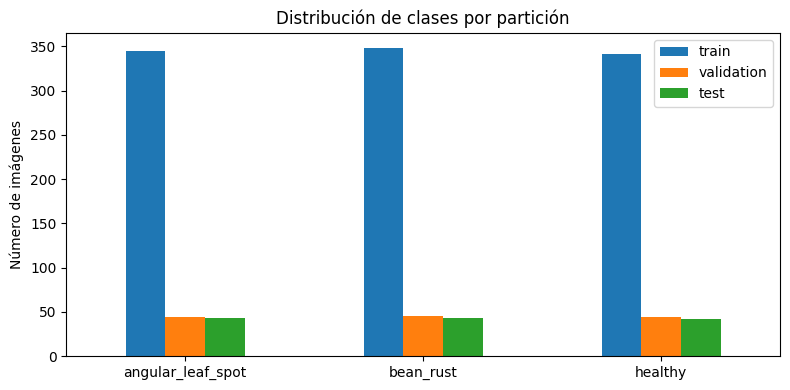

In [4]:
def conteo_por_clase(ds, nombre):
    etiquetas = [int(y) for _, y in np_iter(ds)]
    cuenta = pd.Series(etiquetas).value_counts().sort_index()
    cuenta.index = [class_names[i] for i in cuenta.index]
    cuenta.name = nombre
    return cuenta

distribucion = pd.concat([
    conteo_por_clase(raw_train, "train"),
    conteo_por_clase(raw_val, "validation"),
    conteo_por_clase(raw_test, "test"),
], axis=1)
distribucion["total"] = distribucion.sum(axis=1)
display(distribucion)

distribucion[["train", "validation", "test"]].plot(kind="bar", figsize=(8, 4))
plt.title("Distribución de clases por partición")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

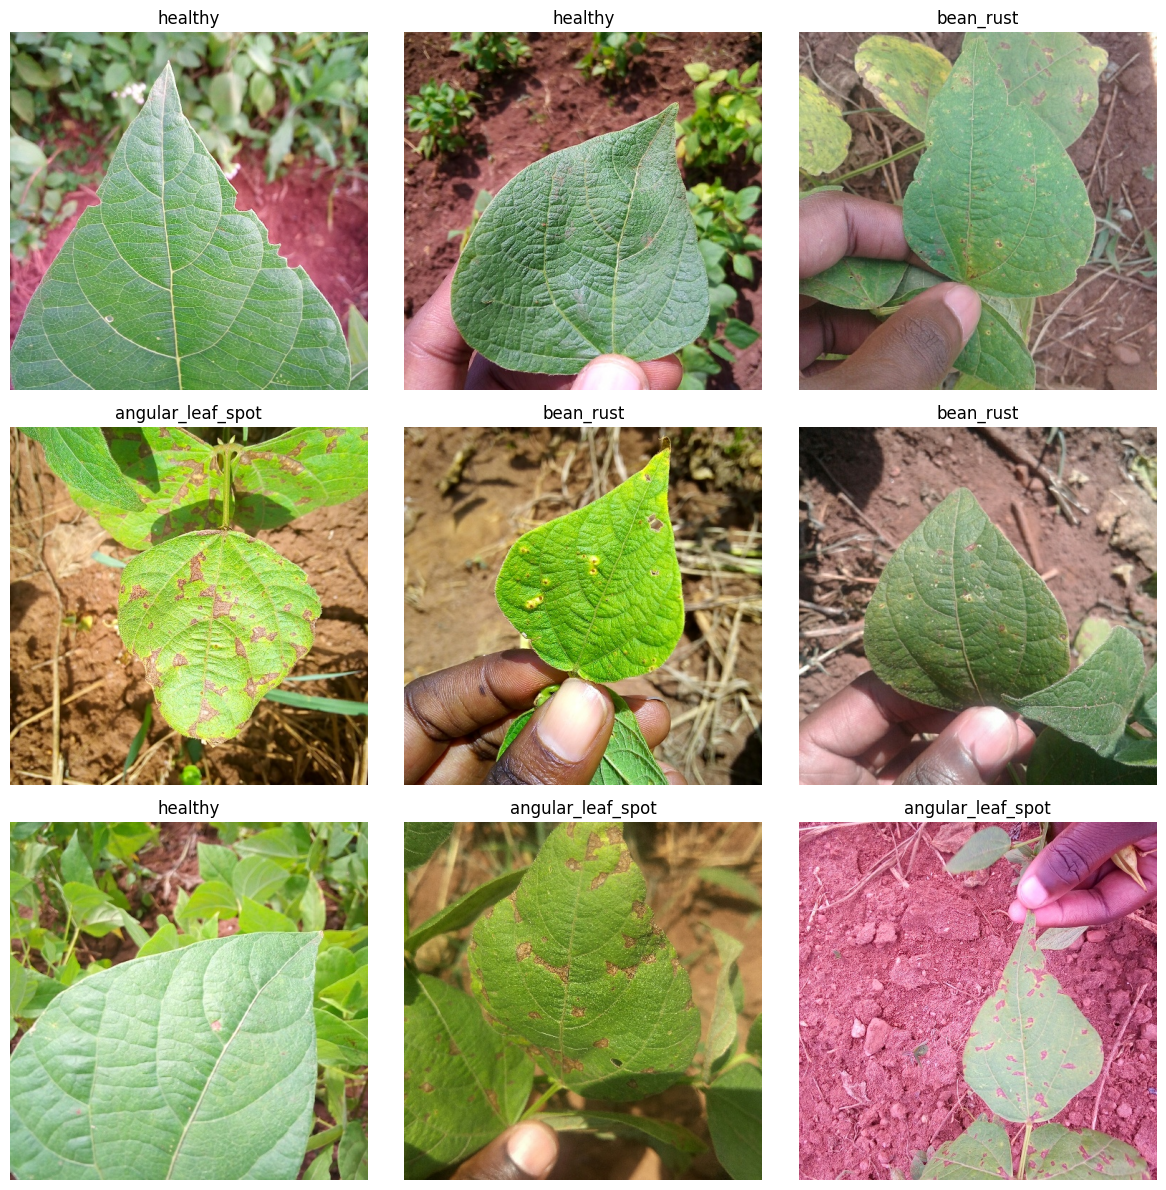

In [5]:
# Muestra de imágenes de entrenamiento por clase (3 por clase)
plt.figure(figsize=(12, 12))
vistas = {c: 0 for c in range(NUM_CLASSES)}
i = 0
for img, label in np_iter(raw_train.shuffle(1034, seed=SEED)):
    label = int(label)
    if vistas[label] < 3:
        plt.subplot(3, 3, i + 1)
        plt.imshow(img)
        plt.title(class_names[label])
        plt.axis("off")
        vistas[label] += 1
        i += 1
    if i == 9:
        break
plt.tight_layout()
plt.show()

In [6]:
# Estadísticas básicas de píxeles (muestra de 200 imágenes de entrenamiento)
muestra = np.stack([img for img, _ in np_iter(raw_train.take(200))]).astype("float32")
print("Forma de la muestra:", muestra.shape)
print("Rango de píxeles:", muestra.min(), "-", muestra.max())
print("Media por canal (R, G, B):", muestra.mean(axis=(0, 1, 2)).round(1))
print("Desv. estándar por canal:", muestra.std(axis=(0, 1, 2)).round(1))
del muestra

Forma de la muestra: (200, 500, 500, 3)
Rango de píxeles: 0.0 - 255.0
Media por canal (R, G, B): [85.9 85.9 58.1]
Desv. estándar por canal: [63.5 69.8 46.7]


**Observaciones del análisis.**
- Las clases están prácticamente balanceadas, por lo que no se necesitan pesos de clase ni remuestreo.
- Todas las imágenes tienen el mismo tamaño (500 x 500 x 3) y valores de 0 a 255.
- Las hojas aparecen con distintos fondos, ángulos e iluminación. Esto hace el problema más realista y también más difícil que un dataset de laboratorio.
- Con solo 1,034 imágenes de entrenamiento, el sobreajuste será el principal riesgo.

## 2.3 Separación de datos y preprocesamiento

El dataset ya trae una separación estándar en entrenamiento, validación y prueba. Se respeta tal cual:
- **Entrenamiento (train):** para ajustar los pesos.
- **Validación (validation):** para comparar modelos, ajustar hiperparámetros y decidir cuál es el mejor.
- **Prueba (test):** solo para la evaluación final. No se usa para tomar decisiones de diseño.

**Preprocesamiento:**
- Redimensionar a 160 x 160 píxeles para reducir el costo de cómputo.
- Lotes de 32 imágenes, con `cache` y `prefetch` para acelerar el entrenamiento.
- La normalización de píxeles se hace **dentro del modelo** (capa `Rescaling`). Así el modelo guardado recibe imágenes con valores de 0 a 255 y la función de predicción no necesita preprocesar a mano.

In [7]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def redimensionar(imagen, etiqueta):
    imagen = tf.image.resize(imagen, IMG_SIZE)   # queda en float32, valores 0-255
    return imagen, etiqueta

train_ds = (raw_train
            .map(redimensionar, num_parallel_calls=AUTOTUNE)
            .cache()
            .shuffle(1034, seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_ds = (raw_val
          .map(redimensionar, num_parallel_calls=AUTOTUNE)
          .cache()
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

test_ds = (raw_test
           .map(redimensionar, num_parallel_calls=AUTOTUNE)
           .cache()
           .batch(BATCH_SIZE)
           .prefetch(AUTOTUNE))

for x, y in train_ds.take(1):
    print("Forma de un lote de imágenes:", x.shape)
    print("Forma de un lote de etiquetas:", y.shape)
    print("Tipo de dato:", x.dtype, "| rango:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

Forma de un lote de imágenes: (32, 160, 160, 3)
Forma de un lote de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'> | rango: 0.0 - 255.0


# 3. Desarrollo del modelo

## 3.1 Funciones auxiliares

Se definen funciones para graficar las curvas de entrenamiento y evaluar cada modelo de la misma manera, para que la comparación sea justa.

In [8]:
def graficar_historial(history, titulo="", marcar_epoca=None):
    h = history.history
    epocas = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epocas, h["accuracy"], label="train")
    ax[0].plot(epocas, h["val_accuracy"], label="validación")
    ax[0].set_title(f"Accuracy {titulo}")
    ax[0].set_xlabel("Época")
    ax[0].legend()

    ax[1].plot(epocas, h["loss"], label="train")
    ax[1].plot(epocas, h["val_loss"], label="validación")
    ax[1].set_title(f"Pérdida {titulo}")
    ax[1].set_xlabel("Época")
    ax[1].legend()

    if marcar_epoca is not None:
        for a in ax:
            a.axvline(marcar_epoca + 0.5, color="gray", linestyle="--")

    plt.tight_layout()
    plt.show()


def evaluar(modelo, ds, nombre):
    loss, acc = modelo.evaluate(ds, verbose=0)
    print(f"{nombre}: loss = {loss:.4f} | accuracy = {acc:.4f}")
    return loss, acc


def predicciones(modelo, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_prob = modelo.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    return y_true, y_pred


def mostrar_matriz(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=20)
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

## 3.2 Modelo base: CNN desde cero

**Arquitectura.** Tres bloques convolucionales seguidos de un clasificador denso:

| Capa | Descripción |
|---|---|
| `Rescaling(1/255)` | lleva los píxeles de 0-255 a 0-1 |
| `Conv2D(32, 3x3, ReLU)` + `MaxPooling2D` | detecta bordes y texturas simples |
| `Conv2D(64, 3x3, ReLU)` + `MaxPooling2D` | combina patrones simples en formas más complejas |
| `Conv2D(128, 3x3, ReLU)` + `MaxPooling2D` | patrones de mayor nivel (manchas, pústulas) |
| `Flatten` | convierte los mapas de características en un vector |
| `Dense(128, ReLU)` | combina las características |
| `Dense(3, softmax)` | probabilidad de cada clase |

**Entrenamiento.** Optimizador Adam, pérdida `sparse_categorical_crossentropy` (las etiquetas son enteros 0, 1, 2) y métrica `accuracy`, durante 20 épocas.

Este modelo **no usa ninguna técnica de regularización a propósito**, para tener un punto de comparación contra las mejoras de la sección 4.

In [9]:
def construir_base():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for filtros in (32, 64, 128):
        x = layers.Conv2D(filtros, 3, activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_base")

modelo_base = construir_base()
modelo_base.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
modelo_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,179 (20.61 MB)

 Trainable params: 5,402,179 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
hist_base = modelo_base.fit(train_ds, validation_data=val_ds, epochs=20, verbose=2)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 25s - 745ms/step - accuracy: 0.5329 - loss: 0.9643 - val_accuracy: 0.6241 - val_loss: 0.8068
Epoch 2/20
33/33 - 1s - 30ms/step - accuracy: 0.7147 - loss: 0.6788 - val_accuracy: 0.6316 - val_loss: 0.8101
Epoch 3/20
33/33 - 1s - 29ms/step - accuracy: 0.6915 - loss: 0.7128 - val_accuracy: 0.7744 - val_loss: 0.5757
Epoch 4/20
33/33 - 1s - 29ms/step - accuracy: 0.7727 - loss: 0.5513 - val_accuracy: 0.7669 - val_loss: 0.4990
Epoch 5/20
33/33 - 1s - 31ms/step - accuracy: 0.7892 - loss: 0.5115 - val_accuracy: 0.7444 - val_loss: 0.5233
Epoch 6/20
33/33 - 1s - 32ms/step - accuracy: 0.7988 - loss: 0.4512 - val_accuracy: 0.7669 - val_loss: 0.4937
Epoch 7/20
33/33 - 1s - 38ms/step - accuracy: 0.8482 - loss: 0.3854 - val_accuracy: 0.7519 - val_loss: 0.5520
Epoch 8/20
33/33 - 1s - 30ms/step - accuracy: 0.8839 - loss: 0.2940 - val_accuracy: 0.7895 - val_loss: 0.5403
Epoch 9/20
33/33 - 1s - 29ms/step - accuracy: 0.9168 - loss: 0.2156 - val_accuracy: 0.7519 - val_loss: 0.7437
Epoch 10/20
33/33 -

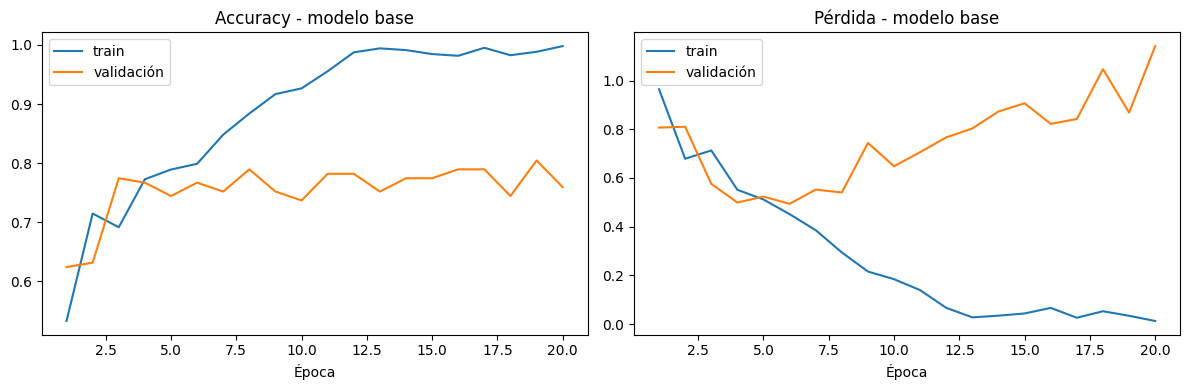

In [11]:
graficar_historial(hist_base, "- modelo base")

## 3.3 Evaluación del modelo base

Se evalúa en entrenamiento, validación y prueba. La **validación** es la que se usa para decidir; la **prueba** se reporta aquí solo para registrar el punto de partida y no se usa para tomar decisiones.

Base - train     : loss = 0.0032 | accuracy = 1.0000
Base - validación: loss = 1.1414 | accuracy = 0.7594
Base - prueba    : loss = 0.9134 | accuracy = 0.7734

                   precision    recall  f1-score   support

angular_leaf_spot      0.867     0.591     0.703        44
        bean_rust      0.694     0.756     0.723        45
          healthy      0.759     0.932     0.837        44

         accuracy                          0.759       133
        macro avg      0.773     0.759     0.754       133
     weighted avg      0.773     0.759     0.754       133



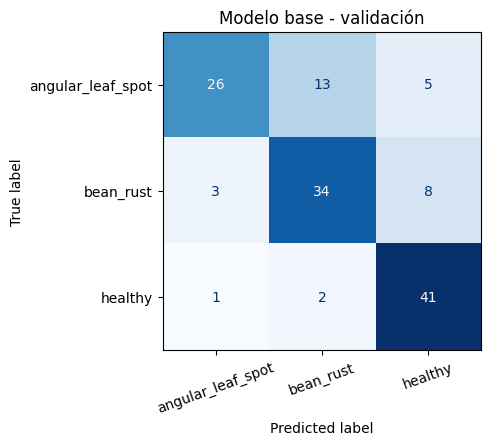

In [12]:
base_train = evaluar(modelo_base, train_ds, "Base - train     ")
base_val = evaluar(modelo_base, val_ds, "Base - validación")
base_test = evaluar(modelo_base, test_ds, "Base - prueba    ")

y_true_val, y_pred_val = predicciones(modelo_base, val_ds)
print()
print(classification_report(y_true_val, y_pred_val, target_names=class_names, digits=3))
mostrar_matriz(y_true_val, y_pred_val, "Modelo base - validación")

**Análisis del modelo base.** El modelo **sobreajusta de forma clara**: llega a 1.000 de exactitud en entrenamiento pero solo 0.759 en validación (brecha de +0.241), y la pérdida de validación termina en 1.14 mientras la de entrenamiento baja a 0.003. Es decir, memorizó las imágenes de entrenamiento en lugar de aprender patrones generales de la enfermedad. Esto era esperable porque:
1. el dataset es pequeño (1,034 imágenes de entrenamiento);
2. la capa `Flatten` seguida de `Dense(128)` concentra la gran mayoría de los 5.4 millones de parámetros del modelo, lo que le da mucha capacidad para memorizar;
3. no hay ninguna técnica de regularización.

Por clase, el punto más débil es `angular_leaf_spot`, con recall de 0.591 en validación: casi 4 de cada 10 hojas con esta enfermedad no se detectan. Estas observaciones motivan las mejoras de la siguiente sección.

# 4. Ajuste del modelo

Se hacen **dos iteraciones**. En cada una se compara contra la anterior usando la exactitud y la pérdida en **validación**.

## 4.1 Iteración 1: regularización y cambios de arquitectura

Cambios respecto al modelo base y motivo de cada uno:

| Cambio | Por qué se espera que ayude |
|---|---|
| **Data augmentation** (volteos, rotación, zoom, contraste) | Genera variaciones nuevas de cada hoja en cada época. Con pocos datos, evita que el modelo memorice fotos concretas. Solo se aplica en entrenamiento. |
| **BatchNormalization** después de cada convolución | Estabiliza y acelera el entrenamiento, y tiene un ligero efecto regularizador. |
| **Regularización L2** (1e-4) en convoluciones y capa densa | Penaliza pesos grandes y favorece modelos más simples. |
| **Dropout** (0.4 y 0.3) | Apaga neuronas al azar durante el entrenamiento, evitando que dependan unas de otras. |
| **GlobalAveragePooling2D** en lugar de `Flatten` | Reduce drásticamente el número de parámetros del clasificador y obliga a cada filtro a representar un patrón en toda la imagen. |
| **Un bloque convolucional más** (256 filtros) | Compensa la pérdida de capacidad al quitar `Flatten`, con muchos menos parámetros. |
| **EarlyStopping** y **ReduceLROnPlateau** | Detienen el entrenamiento cuando la validación deja de mejorar y reducen la tasa de aprendizaje cuando se estanca. |

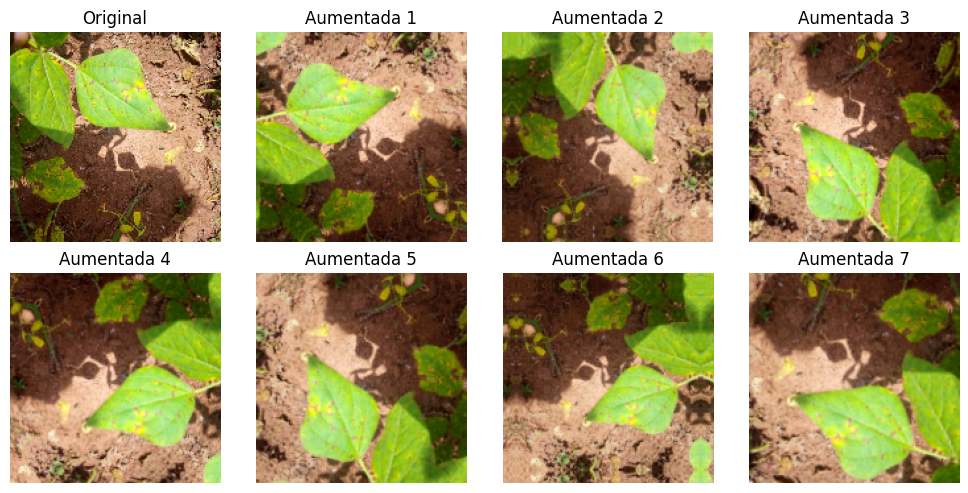

In [13]:
# Capas de data augmentation (solo se activan durante el entrenamiento)
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="augmentation")

# Vista previa del efecto del data augmentation sobre una misma imagen
img_ejemplo, _ = next(iter(np_iter(raw_train.map(redimensionar).take(1))))
plt.figure(figsize=(10, 5))
plt.subplot(2, 4, 1)
plt.imshow(img_ejemplo.astype("uint8"))
plt.title("Original")
plt.axis("off")
for i in range(7):
    aug = augmentation(np.expand_dims(img_ejemplo, 0), training=True)
    plt.subplot(2, 4, i + 2)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.title(f"Aumentada {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [14]:
def bloque_conv(x, filtros, l2=1e-4):
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return x

def construir_regularizado():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filtros in (32, 64, 128, 256):
        x = bloque_conv(x, filtros)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_regularizada")

modelo_reg = construir_regularizado()
modelo_reg.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
modelo_reg.summary()

Model: "cnn_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 20, 20, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 406,499 (1.55 MB)

 Trainable params: 405,539 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [15]:
callbacks_reg = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
]

hist_reg = modelo_reg.fit(train_ds, validation_data=val_ds, epochs=60,
                          callbacks=callbacks_reg, verbose=2)

Epoch 1/60


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 11s - 334ms/step - accuracy: 0.5735 - loss: 1.0288 - val_accuracy: 0.3308 - val_loss: 1.4369 - learning_rate: 0.0010
Epoch 2/60
33/33 - 2s - 73ms/step - accuracy: 0.6605 - loss: 0.8126 - val_accuracy: 0.3308 - val_loss: 1.5708 - learning_rate: 0.0010
Epoch 3/60
33/33 - 2s - 70ms/step - accuracy: 0.6847 - loss: 0.7537 - val_accuracy: 0.3609 - val_loss: 1.4153 - learning_rate: 0.0010
Epoch 4/60
33/33 - 2s - 70ms/step - accuracy: 0.7089 - loss: 0.7296 - val_accuracy: 0.3910 - val_loss: 1.2844 - learning_rate: 0.0010
Epoch 5/60
33/33 - 2s - 70ms/step - accuracy: 0.7079 - loss: 0.7290 - val_accuracy: 0.4586 - val_loss: 1.3740 - learning_rate: 0.0010
Epoch 6/60
33/33 - 2s - 71ms/step - accuracy: 0.7244 - loss: 0.6896 - val_accuracy: 0.3910 - val_loss: 1.7461 - learning_rate: 0.0010
Epoch 7/60
33/33 - 2s - 75ms/step - accuracy: 0.7273 - loss: 0.7029 - val_accuracy: 0.4361 - val_loss: 1.7881 - learning_rate: 0.0010
Epoch 8/60
33/33 - 2s - 71ms/step - accuracy: 0.7176 - loss: 0.6990 - v

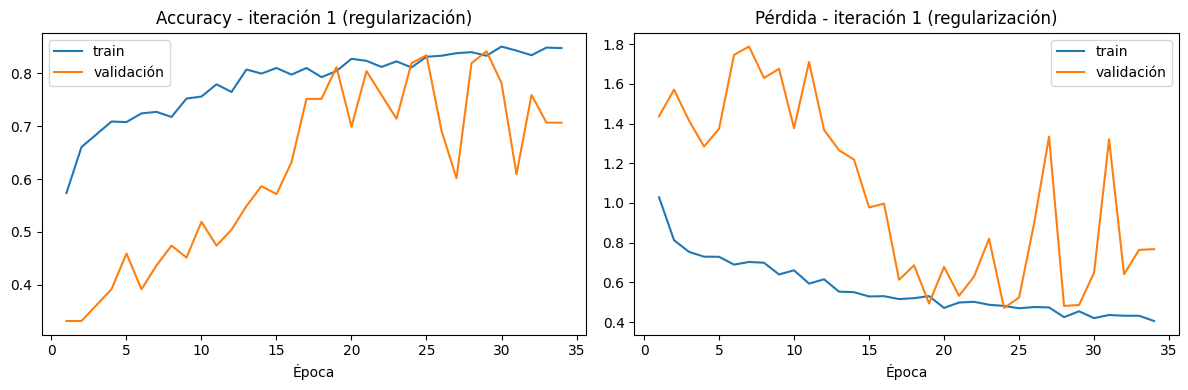

Iter. 1 - train     : loss = 0.4606 | accuracy = 0.8346
Iter. 1 - validación: loss = 0.4710 | accuracy = 0.8195
Iter. 1 - prueba    : loss = 0.4575 | accuracy = 0.8359

                   precision    recall  f1-score   support

angular_leaf_spot      0.966     0.636     0.767        44
        bean_rust      0.688     0.978     0.807        45
          healthy      0.925     0.841     0.881        44

         accuracy                          0.820       133
        macro avg      0.859     0.818     0.818       133
     weighted avg      0.858     0.820     0.818       133



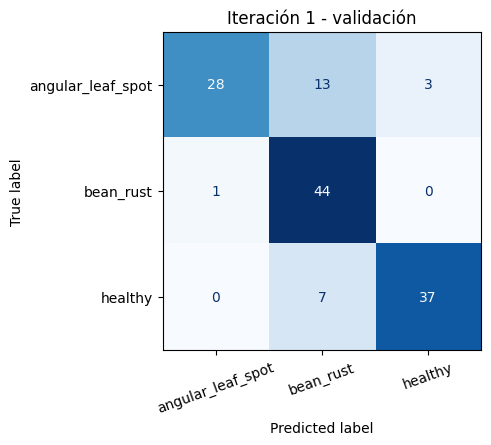

In [16]:
graficar_historial(hist_reg, "- iteración 1 (regularización)")

reg_train = evaluar(modelo_reg, train_ds, "Iter. 1 - train     ")
reg_val = evaluar(modelo_reg, val_ds, "Iter. 1 - validación")
reg_test = evaluar(modelo_reg, test_ds, "Iter. 1 - prueba    ")

y_true_val, y_pred_val = predicciones(modelo_reg, val_ds)
print()
print(classification_report(y_true_val, y_pred_val, target_names=class_names, digits=3))
mostrar_matriz(y_true_val, y_pred_val, "Iteración 1 - validación")

**Análisis de la iteración 1.** La regularización mejoró el modelo en validación (exactitud de 0.759 a 0.820 y pérdida de 1.141 a 0.471) y prácticamente eliminó la brecha entre entrenamiento y validación (de +0.241 a +0.015), con 13 veces menos parámetros (406,499 frente a 5,402,179). Esto confirma que el problema del modelo base era el sobreajuste: el data augmentation, Dropout, L2 y `GlobalAveragePooling2D` impiden que memorice.

Dos observaciones que conviene dejar claras:
- La exactitud de **validación oscila bastante** entre épocas (entre ~0.60 y ~0.84 en las últimas). Con solo 133 imágenes de validación, y con BatchNorm combinado con un data augmentation fuerte, la validación es ruidosa. Por eso se usó `EarlyStopping` con `restore_best_weights`, que se queda con la época de menor pérdida de validación.
- La exactitud de entrenamiento (0.835) es baja: el modelo ya no sobreajusta, pero tampoco aprende lo suficiente. Una CNN entrenada desde cero con ~1,000 imágenes tiene ese límite, porque debe aprender todos sus filtros con pocos ejemplos. Esto motiva la segunda iteración.

## 4.2 Iteración 2: transferencia de aprendizaje (MobileNetV2)

**Idea.** En lugar de aprender todo desde cero, se reutiliza **MobileNetV2** ya entrenada con ImageNet (más de un millón de imágenes). Sus primeras capas ya detectan bordes, texturas y formas, características que también sirven para reconocer manchas y pústulas en una hoja.

**Arquitectura.**
- Data augmentation (la misma de la iteración 1).
- `Rescaling` a rango [-1, 1], que es el que espera MobileNetV2 (`x / 127.5 - 1`).
- Base MobileNetV2 (sin la capa de clasificación original, `include_top=False`).
- `GlobalAveragePooling2D` + `Dropout(0.3)` + `Dense(3, softmax)`.

**Entrenamiento en dos fases.**
1. **Extracción de características:** base congelada, solo se entrena la cabeza nueva (tasa de aprendizaje 1e-3).
2. **Fine tuning:** se descongelan las últimas 30 capas de la base y se continúa con una tasa de aprendizaje muy baja (1e-5), para ajustarlas a las hojas de frijol sin destruir lo aprendido. Las capas `BatchNormalization` se mantienen en modo inferencia.

In [17]:
base_mobilenet = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_mobilenet.trainable = False   # fase 1: base congelada

def construir_transfer():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augmentation(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)       # rango [-1, 1] para MobileNetV2
    x = base_mobilenet(x, training=False)                  # BatchNorm en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_transfer")

modelo_tl = construir_transfer()
modelo_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
modelo_tl.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
# Fase 1: entrenar solo la cabeza
EPOCAS_FASE1 = 15
hist_tl1 = modelo_tl.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_FASE1, verbose=2)

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 - 16s - 491ms/step - accuracy: 0.5638 - loss: 0.9843 - val_accuracy: 0.7669 - val_loss: 0.5910
Epoch 2/15
33/33 - 1s - 39ms/step - accuracy: 0.7340 - loss: 0.6428 - val_accuracy: 0.8120 - val_loss: 0.4515
Epoch 3/15
33/33 - 1s - 39ms/step - accuracy: 0.7679 - loss: 0.5587 - val_accuracy: 0.8271 - val_loss: 0.4070
Epoch 4/15
33/33 - 3s - 78ms/step - accuracy: 0.8182 - loss: 0.4704 - val_accuracy: 0.8421 - val_loss: 0.3485
Epoch 5/15
33/33 - 1s - 41ms/step - accuracy: 0.8124 - loss: 0.4694 - val_accuracy: 0.8421 - val_loss: 0.3602
Epoch 6/15
33/33 - 1s - 40ms/step - accuracy: 0.8298 - loss: 0.4208 - val_accuracy: 0.8647 - val_loss: 0.3227
Epoch 7/15
33/33 - 1s - 40ms/step - accuracy: 0.8395 - loss: 0.3935 - val_accuracy: 0.8571 - val_loss: 0.3367
Epoch 8/15
33/33 - 1s - 39ms/step - accuracy: 0.8356 - loss: 0.4069 - val_accuracy: 0.8797 - val_loss: 0.2936
Epoch 9/15
33/33 - 1s - 38ms/step - accuracy: 0.8530 - loss: 0.3670 - val_accuracy: 0.8797 - val_loss: 0.3012
Epoch 10/15
33/33 -

In [19]:
# Fase 2: fine tuning de las últimas 30 capas de MobileNetV2
base_mobilenet.trainable = True
for capa in base_mobilenet.layers[:-30]:
    capa.trainable = False

print("Capas de la base:", len(base_mobilenet.layers),
      "| entrenables ahora:", sum(c.trainable for c in base_mobilenet.layers))

modelo_tl.compile(optimizer=keras.optimizers.Adam(1e-5),   # tasa muy baja
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

callbacks_tl = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

hist_tl2 = modelo_tl.fit(train_ds, validation_data=val_ds, epochs=20,
                         callbacks=callbacks_tl, verbose=2)

Capas de la base: 154 | entrenables ahora: 30
Epoch 1/20
33/33 - 19s - 564ms/step - accuracy: 0.7718 - loss: 0.5859 - val_accuracy: 0.8797 - val_loss: 0.2779
Epoch 2/20
33/33 - 2s - 52ms/step - accuracy: 0.8056 - loss: 0.4794 - val_accuracy: 0.8722 - val_loss: 0.2868
Epoch 3/20
33/33 - 2s - 57ms/step - accuracy: 0.8133 - loss: 0.4389 - val_accuracy: 0.8722 - val_loss: 0.2867
Epoch 4/20
33/33 - 2s - 50ms/step - accuracy: 0.8472 - loss: 0.3883 - val_accuracy: 0.8722 - val_loss: 0.2824
Epoch 5/20
33/33 - 2s - 48ms/step - accuracy: 0.8433 - loss: 0.3995 - val_accuracy: 0.8571 - val_loss: 0.2852
Epoch 6/20
33/33 - 2s - 48ms/step - accuracy: 0.8433 - loss: 0.3991 - val_accuracy: 0.8496 - val_loss: 0.2934
Epoch 7/20
33/33 - 2s - 48ms/step - accuracy: 0.8501 - loss: 0.3621 - val_accuracy: 0.8571 - val_loss: 0.2925


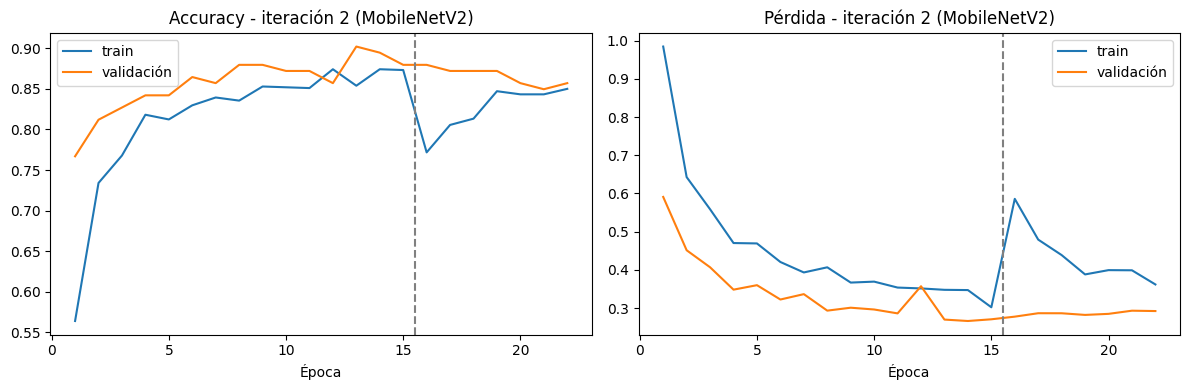

Iter. 2 - train     : loss = 0.3043 | accuracy = 0.8723
Iter. 2 - validación: loss = 0.2779 | accuracy = 0.8797
Iter. 2 - prueba    : loss = 0.2878 | accuracy = 0.9062



                   precision    recall  f1-score   support

angular_leaf_spot      0.892     0.750     0.815        44
        bean_rust      0.837     0.911     0.872        45
          healthy      0.915     0.977     0.945        44

         accuracy                          0.880       133
        macro avg      0.881     0.879     0.877       133
     weighted avg      0.881     0.880     0.877       133



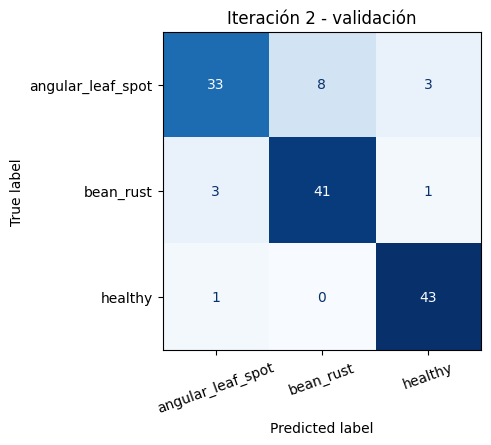

In [20]:
# Se unen las dos fases para graficar
class HistorialUnido:
    def __init__(self, h1, h2):
        self.history = {k: h1.history[k] + h2.history[k] for k in h1.history}

hist_tl = HistorialUnido(hist_tl1, hist_tl2)
graficar_historial(hist_tl, "- iteración 2 (MobileNetV2)", marcar_epoca=EPOCAS_FASE1)

tl_train = evaluar(modelo_tl, train_ds, "Iter. 2 - train     ")
tl_val = evaluar(modelo_tl, val_ds, "Iter. 2 - validación")
tl_test = evaluar(modelo_tl, test_ds, "Iter. 2 - prueba    ")

y_true_val, y_pred_val = predicciones(modelo_tl, val_ds)
print()
print(classification_report(y_true_val, y_pred_val, target_names=class_names, digits=3))
mostrar_matriz(y_true_val, y_pred_val, "Iteración 2 - validación")

**Análisis de la iteración 2.** Reutilizar las características aprendidas por MobileNetV2 en ImageNet fue el cambio que más mejoró el desempeño: exactitud de validación de 0.880 (frente a 0.820 de la iteración 1 y 0.759 del modelo base) y pérdida de validación de 0.278 (frente a 0.471 y 1.141). El modelo parte de filtros que ya detectan bordes y texturas, y solo necesita adaptar una cabeza pequeña a este problema.

Sobre las dos fases de entrenamiento:
- **Fase 1 (base congelada)** fue la que produjo la mejora: la exactitud de validación subió hasta ~0.88-0.90 con solo 3,843 parámetros entrenables.
- **Fase 2 (fine tuning de las últimas 30 capas, tasa 1e-5)** **no aportó una mejora apreciable**: la pérdida de validación no bajó de 0.278 y `EarlyStopping` detuvo el entrenamiento en la época 7, recuperando los pesos de la primera época de esta fase. Es un resultado válido y esperable: con solo 1,034 imágenes, descongelar capas aumenta el riesgo de sobreajuste y las características de ImageNet ya eran suficientemente buenas para este problema.

La brecha entre entrenamiento y validación es de -0.007 (la exactitud de entrenamiento, 0.872, es ligeramente menor que la de validación, 0.880). No indica sobreajuste. Hay que interpretarlo con cuidado: la validación tiene solo 133 imágenes y el modelo todavía tiene margen de mejora (en entrenamiento no llega a 0.90).

In [21]:
tabla = pd.DataFrame({
    "Modelo": ["Base (CNN desde cero)", "Iteración 1 (regularización)", "Iteración 2 (MobileNetV2)"],
    "Parámetros": [modelo_base.count_params(), modelo_reg.count_params(), modelo_tl.count_params()],
    "Train acc": [base_train[1], reg_train[1], tl_train[1]],
    "Val acc": [base_val[1], reg_val[1], tl_val[1]],
    "Val loss": [base_val[0], reg_val[0], tl_val[0]],
    "Test acc": [base_test[1], reg_test[1], tl_test[1]],
    "Brecha train-val": [base_train[1] - base_val[1], reg_train[1] - reg_val[1], tl_train[1] - tl_val[1]],
}).set_index("Modelo")

display(tabla.style.format({
    "Parámetros": "{:,.0f}", "Train acc": "{:.3f}", "Val acc": "{:.3f}",
    "Val loss": "{:.3f}", "Test acc": "{:.3f}", "Brecha train-val": "{:+.3f}",
}))

mejor = tabla["Val acc"].idxmax()
print(f"\nModelo elegido por exactitud de VALIDACIÓN: {mejor}")

,Parámetros,Train acc,Val acc,Val loss,Test acc,Brecha train-val
Modelo,,,,,,
Base (CNN desde cero),"5,402,179",1.000,0.759,1.141,0.773,+0.241
Iteración 1 (regularización),"406,499",0.835,0.820,0.471,0.836,+0.015
Iteración 2 (MobileNetV2),"2,261,827",0.872,0.880,0.278,0.906,-0.007



Modelo elegido por exactitud de VALIDACIÓN: Iteración 2 (MobileNetV2)


## 4.4 Qué cambios funcionaron y por qué

Resumen con los números de esta ejecución (validación, que es el conjunto usado para decidir):

| Cambio | Exactitud de validación | Pérdida de validación | Brecha train-val | ¿Funcionó? |
|---|---|---|---|---|
| Modelo base | 0.759 | 1.141 | +0.241 | punto de partida (sobreajusta) |
| Iteración 1: regularización | 0.820 | 0.471 | +0.015 | **Sí**: eliminó el sobreajuste |
| Iteración 2: MobileNetV2 | 0.880 | 0.278 | -0.007 | **Sí**: mayor mejora |

1. **Regularización (modelo base a iteración 1): funcionó.** La causa del problema era el sobreajuste (brecha de +0.241 y pérdida de validación creciendo). Data augmentation crea variaciones nuevas de cada hoja en cada época, Dropout y L2 limitan la capacidad efectiva de la red, `GlobalAveragePooling2D` reemplaza al `Flatten` que concentraba los parámetros (de 5.4 millones a 0.4 millones) y BatchNorm estabiliza el entrenamiento. El resultado fue una brecha de solo +0.015 y una mejora de 6 puntos porcentuales en validación.
2. **Transferencia de aprendizaje (iteración 1 a iteración 2): funcionó.** Aunque se regularice, una CNN desde cero con ~1,000 imágenes se queda en ~0.83 de exactitud de entrenamiento porque no tiene suficientes ejemplos para aprender buenos filtros. MobileNetV2 ya trae filtros útiles de ImageNet, y con ellos se llegó a 0.880 en validación (+6 puntos) y a una pérdida de validación 41% menor.
3. **Fine tuning: no mejoró.** Se probó descongelar las últimas 30 capas con tasa de aprendizaje baja, pero la pérdida de validación no mejoró y `EarlyStopping` detuvo la fase en la época 7. La mejora vino de la transferencia de aprendizaje con la base congelada, no del fine tuning.
4. **Callbacks.** `EarlyStopping` evitó entrenar de más y recuperó los mejores pesos; `ReduceLROnPlateau` redujo la tasa de aprendizaje cuando la validación se estancó (en la iteración 1 llegó de 1e-3 a ~3e-5).

**Modelo elegido:** Iteración 2 (MobileNetV2), por tener la mayor exactitud y la menor pérdida en validación.

# 5. Resultados

El modelo final se elige por su exactitud en **validación** (sección 4.3). Aquí se evalúa **una sola vez** con el conjunto de **prueba**, que el modelo nunca usó para entrenar ni para tomar decisiones.

In [22]:
modelos = {
    "Base (CNN desde cero)": modelo_base,
    "Iteración 1 (regularización)": modelo_reg,
    "Iteración 2 (MobileNetV2)": modelo_tl,
}
modelo_final = modelos[mejor]
print("Modelo final:", mejor)
print("Nombre interno:", modelo_final.name)

# Se guarda arquitectura + pesos en formato .keras
modelo_final.save("modelo_final.keras")
print("Guardado: modelo_final.keras  (%.1f MB)" % (os.path.getsize("modelo_final.keras") / 1e6))

Modelo final: Iteración 2 (MobileNetV2)
Nombre interno: mobilenetv2_transfer
Guardado: modelo_final.keras  (21.9 MB)


In [23]:
# Se vuelve a cargar desde el archivo para comprobar que se guardó correctamente
modelo_cargado = keras.models.load_model("modelo_final.keras")
loss_test, acc_test = evaluar(modelo_cargado, test_ds, "Modelo final cargado desde .keras - PRUEBA")

Modelo final cargado desde .keras - PRUEBA: loss = 0.2878 | accuracy = 0.9062


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


                   precision    recall  f1-score   support

angular_leaf_spot      0.950     0.884     0.916        43
        bean_rust      0.900     0.837     0.867        43
          healthy      0.875     1.000     0.933        42

         accuracy                          0.906       128
        macro avg      0.908     0.907     0.905       128
     weighted avg      0.909     0.906     0.905       128



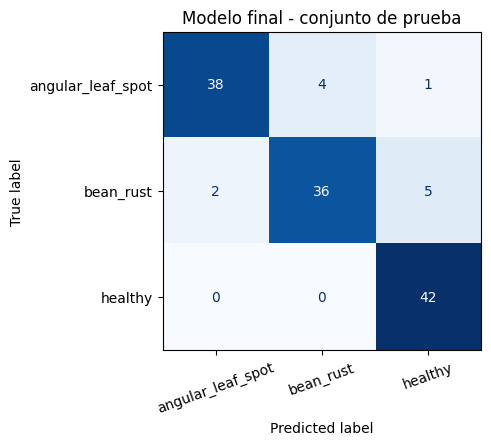

Imágenes mal clasificadas: 12 de 128


In [24]:
y_true_test, y_pred_test = predicciones(modelo_cargado, test_ds)

print(classification_report(y_true_test, y_pred_test, target_names=class_names, digits=3))
mostrar_matriz(y_true_test, y_pred_test, "Modelo final - conjunto de prueba")

errores = int((y_true_test != y_pred_test).sum())
print(f"Imágenes mal clasificadas: {errores} de {len(y_true_test)}")

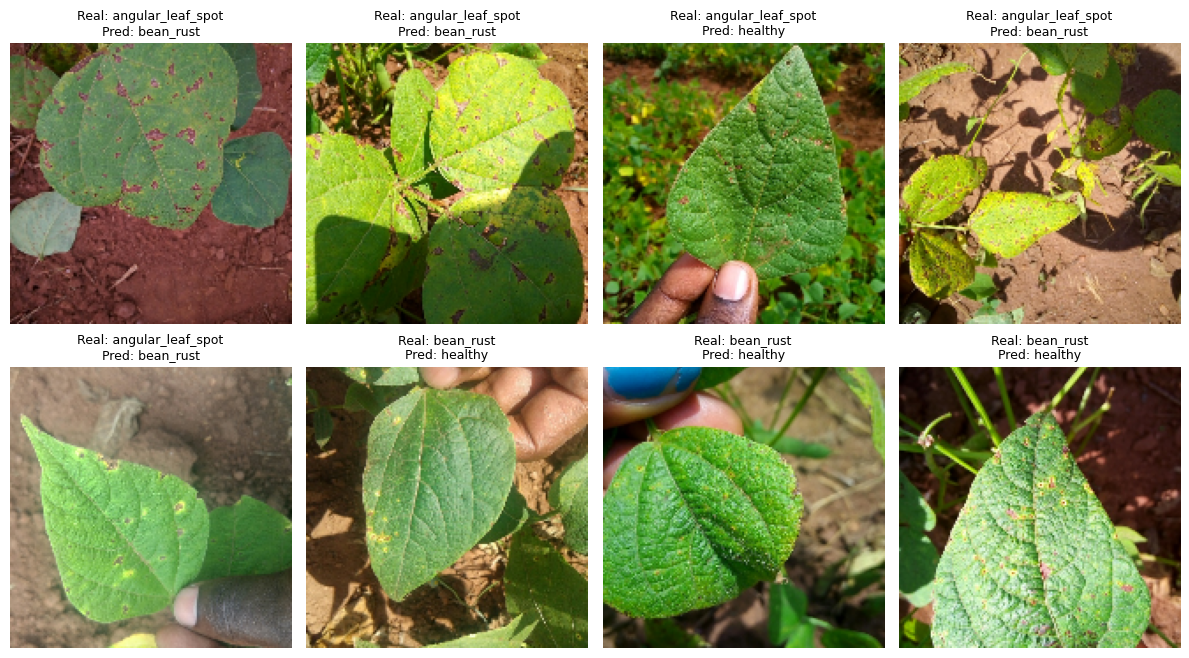

In [25]:
# Ejemplos mal clasificados en prueba
idx_error = np.where(y_true_test != y_pred_test)[0]
imgs_test = np.stack([img for img, _ in np_iter(raw_test.map(redimensionar))])

if len(idx_error) == 0:
    print("El modelo no cometió errores en el conjunto de prueba.")
else:
    n = min(8, len(idx_error))
    plt.figure(figsize=(3 * min(n, 4), 3.4 * ((n + 3) // 4)))
    for k, i in enumerate(idx_error[:n]):
        plt.subplot((n + 3) // 4, 4, k + 1)
        plt.imshow(imgs_test[i].astype("uint8"))
        plt.title(f"Real: {class_names[y_true_test[i]]}\nPred: {class_names[y_pred_test[i]]}", fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [26]:
# Resumen automático del resultado final
rep = classification_report(y_true_test, y_pred_test, target_names=class_names, output_dict=True)
print(f"Modelo final: {mejor}")
print(f"Exactitud en prueba: {acc_test:.3f}")
print(f"F1 macro en prueba: {rep['macro avg']['f1-score']:.3f}")
peor_clase = min(class_names, key=lambda c: rep[c]["f1-score"])
print(f"Clase con menor F1: {peor_clase} ({rep[peor_clase]['f1-score']:.3f})")

Modelo final: Iteración 2 (MobileNetV2)
Exactitud en prueba: 0.906
F1 macro en prueba: 0.905
Clase con menor F1: bean_rust (0.867)


# 6. Conclusiones

**Resumen.** Se construyó un clasificador de enfermedades en hojas de frijol con Keras y TensorFlow, partiendo de un dataset real de campo. Se compararon tres modelos y el mejor, MobileNetV2 con transferencia de aprendizaje, obtuvo **0.906 de exactitud en el conjunto de prueba** (116 de 128 imágenes correctas, F1 macro de 0.905). La progresión en prueba fue 0.773 (base), 0.836 (regularización) y 0.906 (MobileNetV2), consistente con lo observado en validación (0.759, 0.820 y 0.880).

**Análisis de resultados.**
- El modelo base sobreajustó (1.000 en entrenamiento contra 0.759 en validación). La regularización eliminó ese sobreajuste y la transferencia de aprendizaje fue el cambio más efectivo, porque reutiliza características visuales aprendidas con millones de imágenes. El fine tuning no aportó mejora adicional.
- En el modelo final, `healthy` es la clase mejor detectada (recall de 1.000 en prueba), mientras que `bean_rust` tiene el menor F1 (0.867, recall de 0.837). Esto significa que algunas hojas enfermas se clasifican como sanas, un error importante en la práctica porque una enfermedad no detectada puede propagarse.
- Al probar una fotografía subida manualmente (fuera del dataset), el modelo predijo `bean_rust` con solo 51.6% de confianza. Es una señal de que el desempeño baja con fotos distintas a las de entrenamiento (otra cámara, fondo o iluminación), y de que una probabilidad baja puede usarse para pedir una revisión humana.

**Limitaciones.**
- Los conjuntos de validación (133) y prueba (128) son pequeños: una imagen de diferencia cambia ~0.8 puntos porcentuales de exactitud, por lo que los resultados tienen incertidumbre.
- Todas las fotos provienen de una misma región y condiciones de cultivo; no se garantiza el mismo desempeño con otras variedades de frijol, otras cámaras u otros climas.
- Solo se distinguen tres clases; el modelo no detecta otras enfermedades ni sabe reconocer imágenes que no sean hojas de frijol.

**Posibles mejoras.**
- Usar validación cruzada para tener estimaciones más estables.
- Probar arquitecturas más grandes (EfficientNet, ResNet) y mayor resolución de entrada.
- Buscar los hiperparámetros de forma sistemática (por ejemplo con KerasTuner), incluyendo cuántas capas descongelar en el fine tuning.
- Agregar más datos de otras regiones, más clases de enfermedades y una clase "no es una hoja de frijol".
- Convertir el modelo a TensorFlow Lite para usarlo directo en un celular en campo.

# 7. Aplicación

La función `predecir(ruta_imagen)` recibe la **ruta de una imagen**, la carga, la redimensiona y regresa la **clase predicha** y su **probabilidad**, mostrando además la imagen y las probabilidades de cada clase. No hace falta normalizar nada a mano porque el modelo ya incluye la capa `Rescaling`.

Primero se guardan algunas imágenes de prueba como archivos en la carpeta `ejemplos/` (también se incluyen en el repositorio).

In [27]:
os.makedirs("ejemplos", exist_ok=True)

# Se guardan 2 imágenes de prueba por clase como archivos .jpg
guardadas = {c: 0 for c in range(NUM_CLASSES)}
for img, label in np_iter(raw_test):
    label = int(label)
    if guardadas[label] < 2:
        guardadas[label] += 1
        ruta = f"ejemplos/{class_names[label]}_{guardadas[label]}.jpg"
        keras.utils.save_img(ruta, img)
    if all(v == 2 for v in guardadas.values()):
        break

print(sorted(os.listdir("ejemplos")))

['angular_leaf_spot_1.jpg', 'angular_leaf_spot_2.jpg', 'bean_rust_1.jpg', 'bean_rust_2.jpg', 'healthy_1.jpg', 'healthy_2.jpg']


In [28]:
def predecir(ruta_imagen, modelo=None, mostrar=True):
    # Recibe la ruta de una imagen de hoja de frijol y regresa (clase, probabilidad).
    if modelo is None:
        modelo = modelo_cargado
    img = keras.utils.load_img(ruta_imagen, target_size=IMG_SIZE)     # carga y redimensiona
    arr = keras.utils.img_to_array(img)                                 # valores 0-255
    arr = np.expand_dims(arr, axis=0)                                   # forma (1, 160, 160, 3)

    probs = modelo.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    clase, confianza = class_names[idx], float(probs[idx])

    if mostrar:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
        ax[0].imshow(img)
        ax[0].set_title(f"Predicción: {clase} ({confianza:.1%})")
        ax[0].axis("off")
        ax[1].barh(class_names, probs)
        ax[1].set_xlim(0, 1)
        ax[1].set_title("Probabilidad por clase")
        plt.tight_layout()
        plt.show()
    return clase, confianza

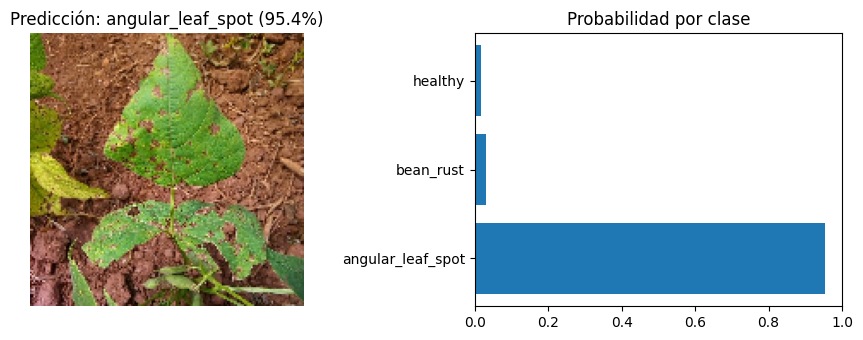

angular_leaf_spot_1.jpg: real = angular_leaf_spot | predicción = angular_leaf_spot (95.4%) -> CORRECTO



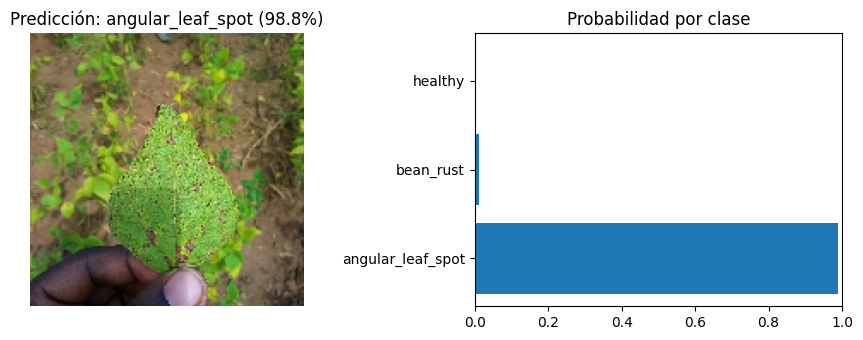

angular_leaf_spot_2.jpg: real = angular_leaf_spot | predicción = angular_leaf_spot (98.8%) -> CORRECTO



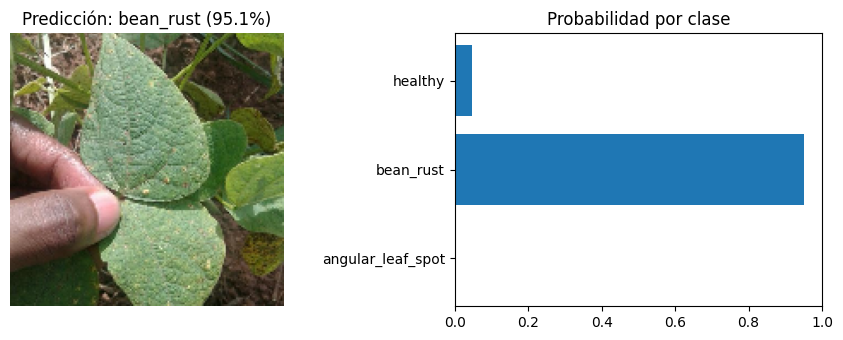

bean_rust_1.jpg: real = bean_rust | predicción = bean_rust (95.1%) -> CORRECTO



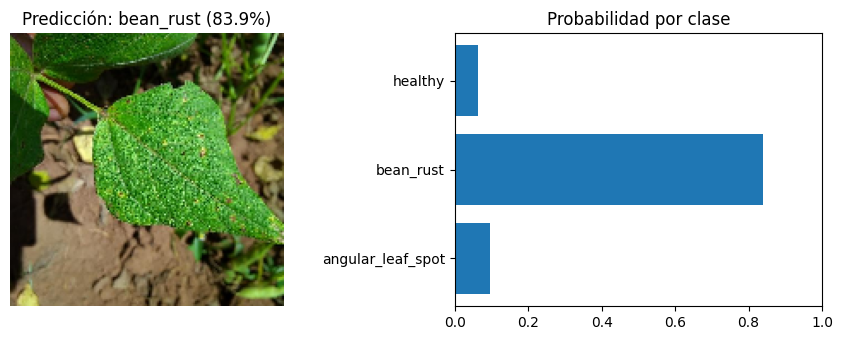

bean_rust_2.jpg: real = bean_rust | predicción = bean_rust (83.9%) -> CORRECTO



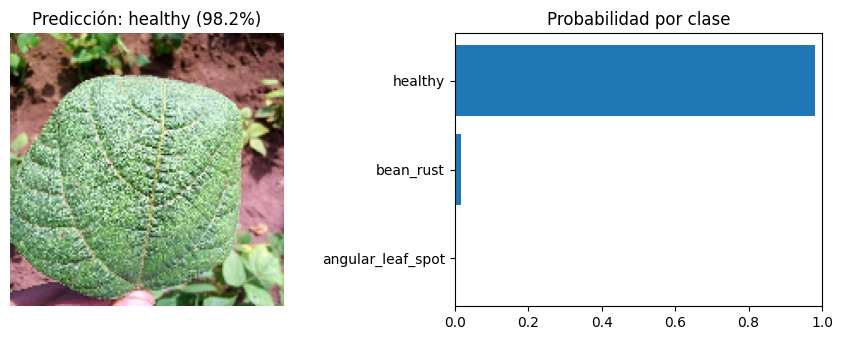

healthy_1.jpg: real = healthy | predicción = healthy (98.2%) -> CORRECTO



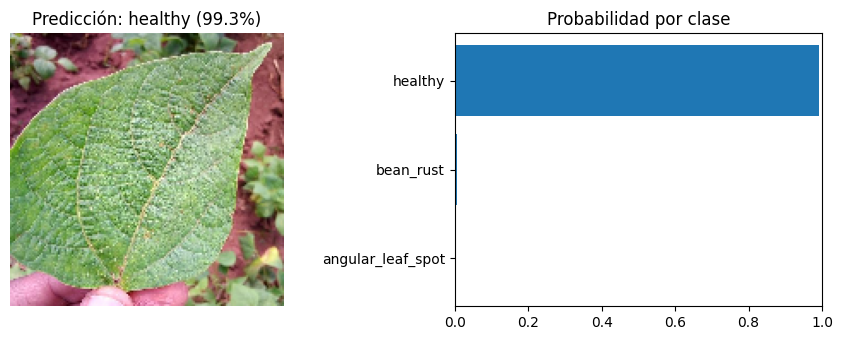

healthy_2.jpg: real = healthy | predicción = healthy (99.3%) -> CORRECTO



In [29]:
# Prueba con las imágenes de la carpeta ejemplos/
for archivo in sorted(os.listdir("ejemplos")):
    ruta = os.path.join("ejemplos", archivo)
    real = archivo.rsplit("_", 1)[0]
    clase, conf = predecir(ruta)
    estado = "CORRECTO" if clase == real else "INCORRECTO"
    print(f"{archivo}: real = {real} | predicción = {clase} ({conf:.1%}) -> {estado}\n")

Saving 2CiruJCvnN4WqvQrY1A8kRg6MALpwAQljLEglCBKAvhKiS0jqN4rrpAdzV2rXcxllftp1g0HUCbeubAeIRS0kIn9nyIW1ztb325vSGETaQDxmOLZvrmqSUfclrNN.jpg to 2CiruJCvnN4WqvQrY1A8kRg6MALpwAQljLEglCBKAvhKiS0jqN4rrpAdzV2rXcxllftp1g0HUCbeubAeIRS0kIn9nyIW1ztb325vSGETaQDxmOLZvrmqSUfclrNN.jpg


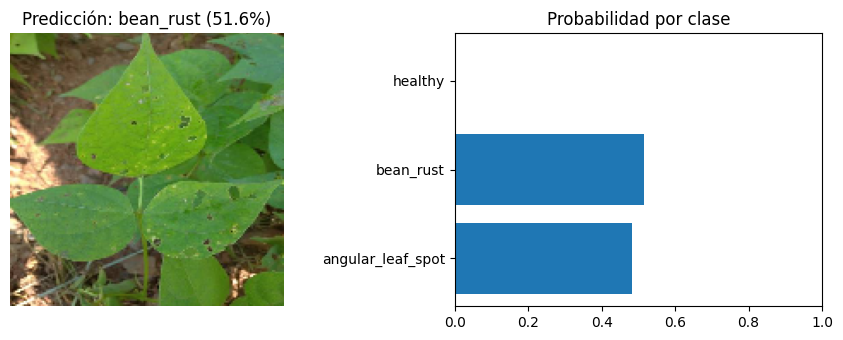

2CiruJCvnN4WqvQrY1A8kRg6MALpwAQljLEglCBKAvhKiS0jqN4rrpAdzV2rXcxllftp1g0HUCbeubAeIRS0kIn9nyIW1ztb325vSGETaQDxmOLZvrmqSUfclrNN.jpg: bean_rust (51.6%)


In [30]:
try:
    from google.colab import files
    subidas = files.upload()
    for nombre in subidas:
        clase, conf = predecir(nombre)
        print(f"{nombre}: {clase} ({conf:.1%})")
except ImportError:

**Observación.** Con las imágenes de la carpeta `ejemplos/` (tomadas del conjunto de prueba) el modelo acertó las 6, con confianza de entre 84% y 99%. Con la foto subida manualmente la confianza fue de solo 51.6%, lo que indica que el modelo se desempeña peor con imágenes diferentes a las del dataset (ver limitaciones en la sección 6).